In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Project directory
PROJECT_DIR = Path.cwd().parent

# Dataset path
DATA_PATH = PROJECT_DIR / "data" / "raw" / "marketing-campaigns-v1.0.0-analysis.csv"

# Load dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (11240, 9)


In [2]:
display(df.head(10))

,spend_date,campaign_id,channel,impressions,clicks,leads,conversions,spend,revenue
0,2023-06-17,CMP0001,paid_search,12218,548,29,4,219.93,2106.19
1,2023-06-18,CMP0001,paid_search,10087,356,19,3,181.57,1383.62
2,2023-06-19,CMP0001,paid_search,15531,476,17,1,279.57,0.00
3,2023-06-20,CMP0001,paid_search,14314,499,30,6,257.66,3137.14
4,2023-06-21,CMP0001,paid_search,10752,285,15,1,193.55,0.00
5,2023-06-22,CMP0001,paid_search,11897,414,20,3,214.16,1180.78
6,2023-06-23,CMP0001,paid_search,11056,424,24,6,199.01,1734.88
7,2023-06-24,CMP0001,paid_search,9043,292,20,2,162.78,0.00
8,2023-06-25,CMP0001,paid_search,10440,256,17,3,187.92,0.00
9,2023-06-26,CMP0001,paid_search,9562,431,30,4,172.12,0.00


In [3]:
print("Columns:")
for col in df.columns:
    print(col)

Columns:
spend_date
campaign_id
channel
impressions
clicks
leads
conversions
spend
revenue


In [4]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 11240 entries, 0 to 11239
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   spend_date   11240 non-null  str    
 1   campaign_id  11240 non-null  str    
 2   channel      11240 non-null  str    
 3   impressions  11240 non-null  int64  
 4   clicks       11240 non-null  int64  
 5   leads        11240 non-null  int64  
 6   conversions  11240 non-null  int64  
 7   spend        11240 non-null  float64
 8   revenue      11240 non-null  float64
dtypes: float64(2), int64(4), str(3)
memory usage: 1.0 MB

Missing Values:
spend_date     0
campaign_id    0
channel        0
impressions    0
clicks         0
leads          0
conversions    0
spend          0
revenue        0
dtype: int64

Duplicate Rows: 0


In [5]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
impressions,11240.0,38865.197420,27384.131292,2565.00,17993.750,31236.000,54272.7500,175793.00
clicks,11240.0,631.878915,542.253194,17.00,242.750,492.000,842.0000,4126.00
leads,11240.0,23.281495,11.656338,0.00,12.000,26.000,35.0000,35.00
conversions,11240.0,3.531673,2.475913,0.00,2.000,3.000,5.0000,14.00
spend,11240.0,402.406585,231.122682,37.14,236.375,369.530,524.3475,1478.36
revenue,11240.0,1918.313079,1984.423965,0.00,0.000,1538.285,3055.4100,16117.44


In [6]:
print(df.isnull().sum())

spend_date     0
campaign_id    0
channel        0
impressions    0
clicks         0
leads          0
conversions    0
spend          0
revenue        0
dtype: int64


In [7]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11240 entries, 0 to 11239
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   spend_date   11240 non-null  str    
 1   campaign_id  11240 non-null  str    
 2   channel      11240 non-null  str    
 3   impressions  11240 non-null  int64  
 4   clicks       11240 non-null  int64  
 5   leads        11240 non-null  int64  
 6   conversions  11240 non-null  int64  
 7   spend        11240 non-null  float64
 8   revenue      11240 non-null  float64
dtypes: float64(2), int64(4), str(3)
memory usage: 1.0 MB


In [9]:
df["spend_date"] = pd.to_datetime(df["spend_date"])

print(df["spend_date"].dtype)

datetime64[us]


In [2]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "raw"
    / "marketing-campaigns-v1.0.0-analysis.csv"
)

df = pd.read_csv(DATA_PATH)
df["spend_date"] = pd.to_datetime(df["spend_date"])

print("Dataset loaded:", df.shape)

Dataset loaded: (11240, 9)


In [3]:
print("Negative Revenue:", (df["revenue"] < 0).sum())

Negative Revenue: 0


In [4]:
print("Clicks > Impressions:", (df["clicks"] > df["impressions"]).sum())

Clicks > Impressions: 0


In [5]:
print("Leads > Clicks:", (df["leads"] > df["clicks"]).sum())

Leads > Clicks: 0


In [6]:
print(
    "Conversions > Leads:",
    (df["conversions"] > df["leads"]).sum()
)

Conversions > Leads: 0


In [7]:
print(
    "Conversions > 0 but Revenue = 0:",
    ((df["conversions"] > 0) & (df["revenue"] == 0)).sum()
)

Conversions > 0 but Revenue = 0: 2086


In [8]:
zero_revenue = df[
    (df["conversions"] > 0) &
    (df["revenue"] == 0)
]

display(zero_revenue.head(5))

,spend_date,campaign_id,channel,impressions,clicks,leads,conversions,spend,revenue
2,2023-06-19,CMP0001,paid_search,15531,476,17,1,279.57,0.0
4,2023-06-21,CMP0001,paid_search,10752,285,15,1,193.55,0.0
7,2023-06-24,CMP0001,paid_search,9043,292,20,2,162.78,0.0
8,2023-06-25,CMP0001,paid_search,10440,256,17,3,187.92,0.0
9,2023-06-26,CMP0001,paid_search,9562,431,30,4,172.12,0.0


In [2]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "raw"
    / "marketing-campaigns-v1.0.0-analysis.csv"
)

df = pd.read_csv(DATA_PATH)
df["spend_date"] = pd.to_datetime(df["spend_date"])

print("Dataset loaded successfully:", df.shape)

Dataset loaded successfully: (11240, 9)


In [3]:
total_spend = df["spend"].sum()

print("Total Marketing Spend:", round(total_spend, 2))

Total Marketing Spend: 4523050.02


In [4]:
total_revenue = df["revenue"].sum()

print("Total Revenue:", round(total_revenue, 2))

Total Revenue: 21561839.01


In [5]:
total_impressions = df["impressions"].sum()

print("Total Impressions:", total_impressions)

Total Impressions: 436844819


In [6]:
total_clicks = df["clicks"].sum()

print("Total Clicks:", total_clicks)

Total Clicks: 7102319


In [7]:
total_leads = df["leads"].sum()

print("Total Leads:", total_leads)

Total Leads: 261684


In [8]:
total_conversions = df["conversions"].sum()

print("Total Conversions:", total_conversions)

Total Conversions: 39696


In [9]:
ctr = (total_clicks / total_impressions) * 100

print("Click-Through Rate (CTR):", round(ctr, 2), "%")

Click-Through Rate (CTR): 1.63 %


In [10]:
conversion_rate = (total_conversions / total_clicks) * 100

print(f"Conversion Rate (CVR): {conversion_rate:.2f} %")

Conversion Rate (CVR): 0.56 %


In [11]:
cpc = total_spend / total_clicks

print(f"Cost Per Click (CPC): {cpc:.2f}")

Cost Per Click (CPC): 0.64


In [12]:
cpl = total_spend / total_leads

print(f"Cost Per Lead (CPL): {cpl:.2f}")

Cost Per Lead (CPL): 17.28


In [13]:
cac = total_spend / total_conversions

print(f"Customer Acquisition Cost (CAC): {cac:.2f}")

Customer Acquisition Cost (CAC): 113.94


In [14]:
roas = total_revenue / total_spend

print(f"Return on Ad Spend (ROAS): {roas:.2f}x")



Return on Ad Spend (ROAS): 4.77x


In [15]:
roi = ((total_revenue - total_spend) / total_spend) * 100

print(f"Return on Investment (ROI): {roi:.2f}%")

Return on Investment (ROI): 376.71%


In [16]:
total_profit = total_revenue - total_spend

print(f"Total Profit: {total_profit:,.2f}")

Total Profit: 17,038,788.99


In [17]:
profit_margin = (total_profit / total_revenue) * 100

print(f"Profit Margin: {profit_margin:.2f}%")

Profit Margin: 79.02%


In [18]:
# Marketing Funnel Analysis

funnel = {
    "Stage": ["Impressions", "Clicks", "Leads", "Conversions"],
    "Count": [
        total_impressions,
        total_clicks,
        total_leads,
        total_conversions
    ]
}

funnel_df = pd.DataFrame(funnel)

funnel_df["Conversion_Rate_%"] = (
    funnel_df["Count"] / funnel_df["Count"].iloc[0]
) * 100

print(funnel_df.to_string(index=False))

      Stage     Count  Conversion_Rate_%
Impressions 436844819         100.000000
     Clicks   7102319           1.625822
      Leads    261684           0.059903
Conversions     39696           0.009087


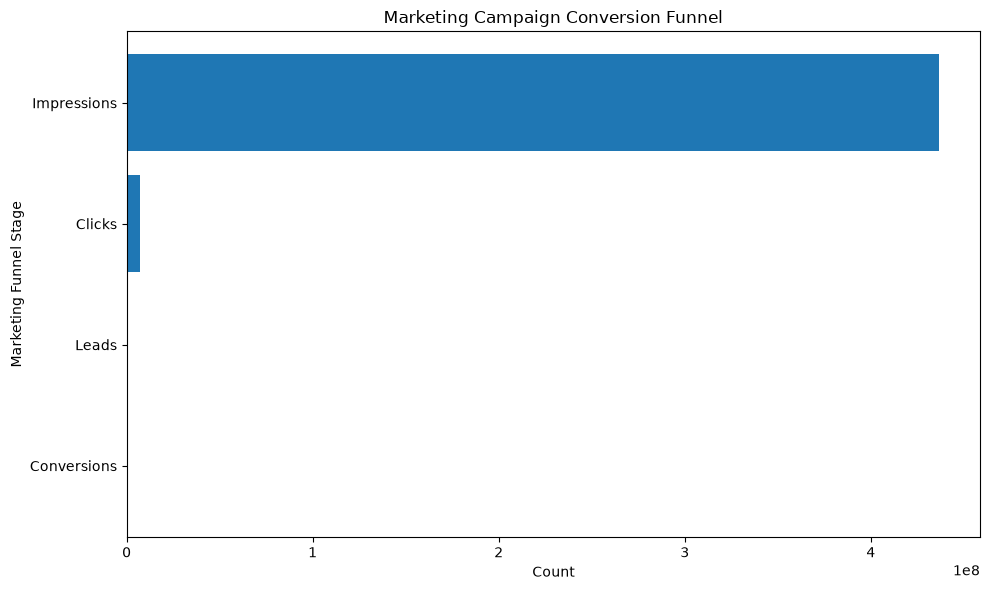

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    funnel_df["Stage"],
    funnel_df["Count"],
)

plt.xlabel("Count")
plt.ylabel("Marketing Funnel Stage")
plt.title("Marketing Campaign Conversion Funnel")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [21]:
print(df.columns.tolist())

['spend_date', 'campaign_id', 'channel', 'impressions', 'clicks', 'leads', 'conversions', 'spend', 'revenue']


In [22]:
campaign_performance = df.groupby("campaign_id").agg(
    Total_Spend=("spend", "sum"),
    Total_Revenue=("revenue", "sum"),
    Total_Clicks=("clicks", "sum"),
    Total_Conversions=("conversions", "sum")
).reset_index()

campaign_performance["ROAS"] = (
    campaign_performance["Total_Revenue"] /
    campaign_performance["Total_Spend"]
)

campaign_performance["CAC"] = (
    campaign_performance["Total_Spend"] /
    campaign_performance["Total_Conversions"].replace(0, float("nan"))
)

print(campaign_performance.round(2).to_string(index=False))

campaign_id  Total_Spend  Total_Revenue  Total_Clicks  Total_Conversions  ROAS    CAC
    CMP0001     13679.39      105014.02         26014                213  7.68  64.22
    CMP0002     47041.22      191521.25         73217                300  4.07 156.80
    CMP0003     30895.96      141758.89         28419                240  4.59 128.73
    CMP0004     27494.98       80962.12         16420                124  2.94 221.73
    CMP0005     17057.46      189914.53         48361                344 11.13  49.59
    CMP0006     35513.84      288606.28         69302                510  8.13  69.63
    CMP0007     34977.43      131491.52         57551                237  3.76 147.58
    CMP0008     62684.63      251896.65         57850                462  4.02 135.68
    CMP0009     54786.64      120655.46         32479                260  2.20 210.72
    CMP0010     57375.18      294187.44        160210                542  5.13 105.86
    CMP0011     40961.29      154659.51         80009 

In [23]:
top_10_roas = campaign_performance.sort_values(
    by="ROAS", ascending=False
).head(10)

print(top_10_roas[
    ["campaign_id", "Total_Revenue", "Total_Spend", "ROAS", "CAC"]
].round(2).to_string(index=False))

campaign_id  Total_Revenue  Total_Spend  ROAS   CAC
    CMP0080      232990.96     17904.18 13.01 45.44
    CMP0070      218374.17     17318.50 12.61 45.46
    CMP0040      183150.82     14920.90 12.27 46.48
    CMP0035      191083.78     15913.35 12.01 46.67
    CMP0045      120094.29     10543.72 11.39 49.27
    CMP0095      203419.10     17881.69 11.38 46.45
    CMP0005      189914.53     17057.46 11.13 49.59
    CMP0050      388919.88     35219.40 11.04 53.44
    CMP0110      330555.85     30384.26 10.88 47.48
    CMP0086      126855.40     11691.91 10.85 55.41


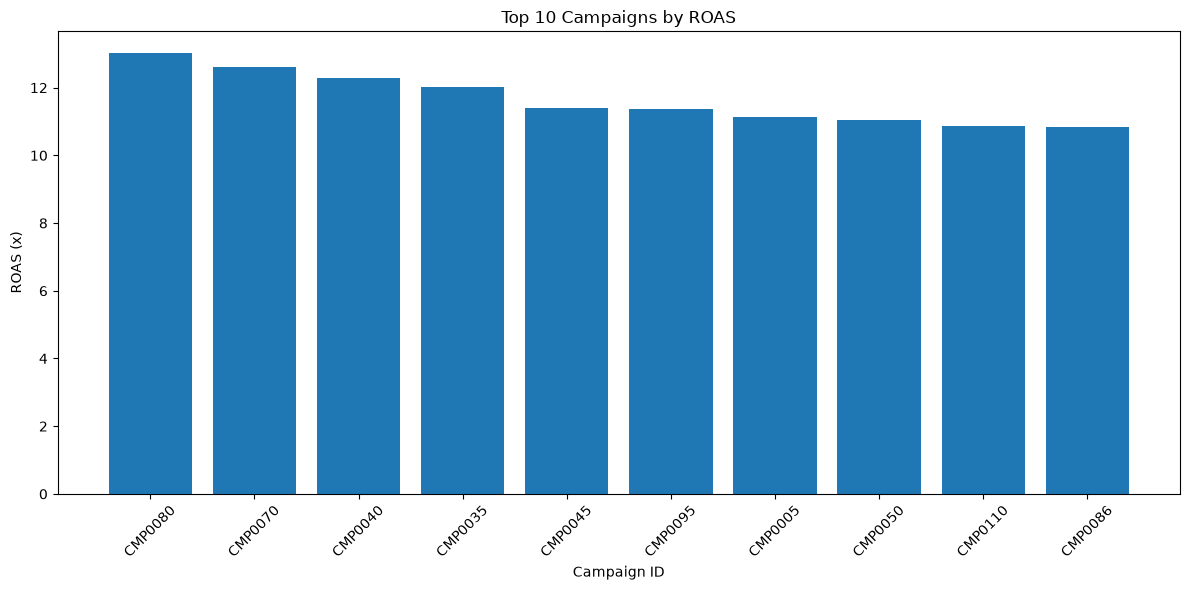

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    top_10_roas["campaign_id"],
    top_10_roas["ROAS"]
)

plt.title("Top 10 Campaigns by ROAS")
plt.xlabel("Campaign ID")
plt.ylabel("ROAS (x)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
channel_performance = df.groupby("channel").agg(
    Total_Spend=("spend", "sum"),
    Total_Revenue=("revenue", "sum"),
    Total_Clicks=("clicks", "sum"),
    Total_Leads=("leads", "sum"),
    Total_Conversions=("conversions", "sum")
).reset_index()

channel_performance["ROAS"] = (
    channel_performance["Total_Revenue"] /
    channel_performance["Total_Spend"]
)

channel_performance["CAC"] = (
    channel_performance["Total_Spend"] /
    channel_performance["Total_Conversions"].replace(0, float("nan"))
)

print(channel_performance.round(2).to_string(index=False))

    channel  Total_Spend  Total_Revenue  Total_Clicks  Total_Leads  Total_Conversions  ROAS    CAC
  affiliate    857835.07     5610700.73       2386856        67849              10352  6.54  82.87
    display    955297.00     3734117.43        879874        45149               6744  3.91 141.65
paid_search    897091.53     5439329.35       1740314        65268              10019  6.06  89.54
paid_social    984731.88     4690137.28       1602785        57619               8648  4.76 113.87
      video    828094.54     2087554.22        492490        25799               3933  2.52 210.55


In [26]:
# Convert spend_date to datetime
df["spend_date"] = pd.to_datetime(df["spend_date"])

# Extract month
df["month"] = df["spend_date"].dt.to_period("M").astype(str)

# Monthly performance
monthly_performance = df.groupby("month").agg(
    Total_Spend=("spend", "sum"),
    Total_Revenue=("revenue", "sum"),
    Total_Clicks=("clicks", "sum"),
    Total_Conversions=("conversions", "sum")
).reset_index()

# Calculate ROAS
monthly_performance["ROAS"] = (
    monthly_performance["Total_Revenue"] /
    monthly_performance["Total_Spend"]
)

print(monthly_performance.round(2).to_string(index=False))

  month  Total_Spend  Total_Revenue  Total_Clicks  Total_Conversions  ROAS
2023-01     23686.55      104789.28         26846                212  4.42
2023-02     49461.61      203501.92         73735                427  4.11
2023-03    104283.65      459636.12        175460                914  4.41
2023-04    104393.90      467059.31        161209                880  4.47
2023-05     97734.10      433096.71        120442                771  4.43
2023-06    123064.68      657294.35        155305               1137  5.34
2023-07    116810.98      688314.91        164873               1220  5.89
2023-08    134065.09      757947.97        199287               1377  5.65
2023-09    155294.61      873286.79        258284               1604  5.62
2023-10    171832.62      982891.87        279402               1648  5.72
2023-11    191171.25      896561.10        305434               1575  4.69
2023-12    186463.37      814229.75        306843               1471  4.37
2024-01    122943.61     

In [27]:
channel_conversion = df.groupby("channel").agg(
    Total_Clicks=("clicks", "sum"),
    Total_Leads=("leads", "sum"),
    Total_Conversions=("conversions", "sum")
).reset_index()

channel_conversion["Click_to_Lead_Rate_%"] = (
    channel_conversion["Total_Leads"] /
    channel_conversion["Total_Clicks"] * 100
)

channel_conversion["Click_to_Conversion_Rate_%"] = (
    channel_conversion["Total_Conversions"] /
    channel_conversion["Total_Clicks"] * 100
)

channel_conversion["Lead_to_Conversion_Rate_%"] = (
    channel_conversion["Total_Conversions"] /
    channel_conversion["Total_Leads"] * 100
)

print(channel_conversion.round(2).to_string(index=False))

    channel  Total_Clicks  Total_Leads  Total_Conversions  Click_to_Lead_Rate_%  Click_to_Conversion_Rate_%  Lead_to_Conversion_Rate_%
  affiliate       2386856        67849              10352                  2.84                        0.43                      15.26
    display        879874        45149               6744                  5.13                        0.77                      14.94
paid_search       1740314        65268              10019                  3.75                        0.58                      15.35
paid_social       1602785        57619               8648                  3.59                        0.54                      15.01
      video        492490        25799               3933                  5.24                        0.80                      15.24


In [28]:
channel_efficiency = df.groupby("channel").agg(
    Impressions=("impressions", "sum"),
    Clicks=("clicks", "sum"),
    Leads=("leads", "sum"),
    Conversions=("conversions", "sum"),
    Spend=("spend", "sum"),
    Revenue=("revenue", "sum")
).reset_index()

channel_efficiency["CTR_%"] = (
    channel_efficiency["Clicks"] /
    channel_efficiency["Impressions"] * 100
)

channel_efficiency["CPC"] = (
    channel_efficiency["Spend"] /
    channel_efficiency["Clicks"]
)

channel_efficiency["CPL"] = (
    channel_efficiency["Spend"] /
    channel_efficiency["Leads"]
)

channel_efficiency["CAC"] = (
    channel_efficiency["Spend"] /
    channel_efficiency["Conversions"]
)

channel_efficiency["ROAS"] = (
    channel_efficiency["Revenue"] /
    channel_efficiency["Spend"]
)

channel_efficiency["Profit_Margin_%"] = (
    (channel_efficiency["Revenue"] -
     channel_efficiency["Spend"]) /
    channel_efficiency["Revenue"] * 100
)

print(channel_efficiency.round(2).to_string(index=False))

    channel  Impressions  Clicks  Leads  Conversions     Spend    Revenue  CTR_%  CPC   CPL    CAC  ROAS  Profit_Margin_%
  affiliate     95314042 2386856  67849        10352 857835.07 5610700.73   2.50 0.36 12.64  82.87  6.54            84.71
    display    146967688  879874  45149         6744 955297.00 3734117.43   0.60 1.09 21.16 141.65  3.91            74.42
paid_search     49837405 1740314  65268        10019 897091.53 5439329.35   3.49 0.52 13.74  89.54  6.06            83.51
paid_social     89520215 1602785  57619         8648 984731.88 4690137.28   1.79 0.61 17.09 113.87  4.76            79.00
      video     55205469  492490  25799         3933 828094.54 2087554.22   0.89 1.68 32.10 210.55  2.52            60.33


In [29]:
# Data quality report

print("Dataset Shape:", df.shape)

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)

print("\nDate Range:")
print("Start Date:", df["spend_date"].min())
print("End Date:", df["spend_date"].max())

Dataset Shape: (11240, 10)

Duplicate Rows: 0

Missing Values:
spend_date     0
campaign_id    0
channel        0
impressions    0
clicks         0
leads          0
conversions    0
spend          0
revenue        0
month          0
dtype: int64

Data Types:
spend_date     datetime64[us]
campaign_id               str
channel                   str
impressions             int64
clicks                  int64
leads                   int64
conversions             int64
spend                 float64
revenue               float64
month                     str
dtype: object

Date Range:
Start Date: 2023-01-04 00:00:00
End Date: 2025-12-02 00:00:00


In [30]:
print("Clicks > Impressions:", (df["clicks"] > df["impressions"]).sum())

print("Leads > Clicks:", (df["leads"] > df["clicks"]).sum())

print("Conversions > Leads:", (df["conversions"] > df["leads"]).sum())

print("Negative Spend:", (df["spend"] < 0).sum())

print("Negative Revenue:", (df["revenue"] < 0).sum())

print("Zero Spend:", (df["spend"] == 0).sum())

print("Zero Impressions:", (df["impressions"] == 0).sum())

Clicks > Impressions: 0
Leads > Clicks: 0
Conversions > Leads: 0
Negative Spend: 0
Negative Revenue: 0
Zero Spend: 0
Zero Impressions: 0


In [31]:
# Export cleaned dataset for Power BI
df.to_csv(
    "marketing_campaign_cleaned.csv",
    index=False
)

print("Dataset exported successfully!")
print("File: marketing_campaign_cleaned.csv")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset exported successfully!
File: marketing_campaign_cleaned.csv
Rows: 11240
Columns: 10


In [32]:
df.to_csv("marketing_campaign_cleaned.csv", index=False)

print("Export successful!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Export successful!
Rows: 11240
Columns: 10


In [33]:
import os

print("Current folder:", os.getcwd())
print("CSV file exists:", os.path.exists("marketing_campaign_cleaned.csv"))
print("File size (MB):", round(os.path.getsize("marketing_campaign_cleaned.csv") / (1024 * 1024), 2))

Current folder: C:\Users\MY PC\Desktop\Marketing-Campaign-Performance-Analytics\notebooks
CSV file exists: True
File size (MB): 0.71
